# Tuning Practice and Comprehensive Problem Solutions

In [ ]:
# Import libraries
# Data processing, manipulation, and analysis libraries
import numpy as np
import numpy.random as random
import pandas as pd

# Visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

# Machine learning library
import sklearn

# Display up to three decimal places
%precision 3

'%.3f'

#### <Practice Question 5-1>
Use a different model (e.g., logistic regression) instead of a decision tree and evaluate its performance using k-fold cross-validation.

In [ ]:
# Answer
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression

# Load breast cancer dataset
cancer = load_breast_cancer()

# Initialize Decision Tree model
model = LogisticRegression(random_state=0)

# Perform 5-fold cross-validation
scores = cross_val_score(model, cancer.data, cancer.target, cv=5)

# Display results
print('Cross validation scores:{}'.format(scores))
print('Cross validation scores:{:.2f}+-{:.2f}'.format(scores.mean(), scores.std()))

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c

Cross validation scores:[0.93  0.939 0.965 0.93  0.956]
Cross validation scores:0.94+-0.01


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


#### <Practice Question 5-2>
Perform grid search and cross-validation on the breast cancer dataset using a decision tree. For the decision tree parameters, set the tree depth and minimum number of samples per leaf as follows: `param_grid = {'max_depth': [2, 3, 4, 5], 'min_samples_leaf': [2, 3, 4, 5]}`

In [ ]:
# Answer
from sklearn.model_selection import GridSearchCV
from sklearn.tree import  DecisionTreeClassifier
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

# Load the data
cancer = load_breast_cancer()

# Split into training and test data
X_train, X_test, y_train, y_test = train_test_split(
    cancer.data, cancer.target, stratify = cancer.target, random_state=0)

# Prepare parameters for GridSearchCV
param_grid = {'max_depth': [2, 3, 4, 5], 'min_samples_leaf': [2, 3, 4, 5]}

# Perform hyperparameter tuning and build the best model
model = DecisionTreeClassifier(random_state=0)
grid_search = GridSearchCV(model, param_grid, cv=5)
grid_search.fit(X_train, y_train)

# Display results
print('Test score:{:.2f}'.format(grid_search.score(X_test, y_test)))
print('Parameters for the best score:{}'.format(grid_search.best_params_))
print('Cross-validation score for the best score:{:.2f}'.format(grid_search.best_score_))

Test score:0.92
Parameters for the best score:{'max_depth': 4, 'min_samples_leaf': 5}
Cross-validation score for the best score:0.94


# Comments
GridSearchCV:
- Tries all parameter combinations
- Uses 5-fold cross-validation (cv=5)
- Evaluates each combination

For each of the 16 combinations:
- Split training data into 5 folds
- Train on 4 folds, validate on 1
- Repeat 5 times and average



---
## 5-2.3 Comprehensive Question

###**Practice Project: Smart Office Occupancy Detection**


You are a Data Scientist at EcoSpace Solutions, an IoT (Internet of Things) startup that retrofits old office buildings with smart energy systems. Your team has installed sensors in a client's meeting rooms to measure Temperature, Humidity, Light intensity, and CO2 levels.

The goal is to automatically turn off the lights and HVAC (air conditioning) when a room is empty to save massive amounts of electricity.

You received the following message from the Lead Project Manager:


"Hi Team,

We need the machine learning model to predict whether a room is Occupied (1) or Empty (0) based on the sensor data. If we can get this right, we will save the client millions in energy costs.

Here is what I need you to do:
1. Run some visualizations on the sensor data. I want to know which sensor is the best indicator of human presence. Should we rely mostly on CO2, or is Light better?
2. Test out a few different algorithms. We need to know this model is robust and won't just fail when deployed to a new floor. Use a reliable testing method.
3. **The client's CEO gave us a strict requirement: The AI must be at least 97% accurate.** If it's less accurate than that, the lights will turn off while people are in meetings, and they will rip our system out of the building. Tinker with the models until you break that 97% threshold.

Can we hit their target?

Project Manager"



Your task is to translate the Project Manager's business requests into a Machine Learning pipeline.

Run the two cells below to install the UCI repository tool and load your dataset.

In [ ]:
!pip install ucimlrepo

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from ucimlrepo import fetch_ucirepo

# Fetch dataset
occupancy = fetch_ucirepo(id=357)

# Combine into one dataframe for easy EDA
df = occupancy.data.features[['Temperature','Humidity','Light','CO2','HumidityRatio']].copy()
df['Occupancy'] = occupancy.data.targets
df = df.apply(pd.to_numeric, errors='coerce')

df.head()

,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy
0,23.18,27.2720,426.0,721.25,0.004793,1.0
1,23.15,27.2675,429.5,714.00,0.004783,1.0
2,23.15,27.2450,426.0,713.50,0.004779,1.0
3,23.15,27.2000,426.0,708.25,0.004772,1.0
4,23.10,27.2000,426.0,704.50,0.004757,1.0


#### Task 1: Explanatory Data Analysis(EDA)

(1) Check the dataset for any missing values, and handle them accordingly.

In [ ]:
# (1)
## WRITE ME
print(df.isnull().sum())
df = df.dropna()
print(df.isnull().sum())

Temperature      2
Humidity         2
Light            2
CO2              2
HumidityRatio    2
Occupancy        2
dtype: int64
Temperature      0
Humidity         0
Light            0
CO2              0
HumidityRatio    0
Occupancy        0
dtype: int64


(2) Create at least two different types of visualizations (e.g. boxplots comparing CO2 levels when Occupied vs Empty, a scatter plot, or a correlation heatmap) using `matplotlib` or `seaborn`.

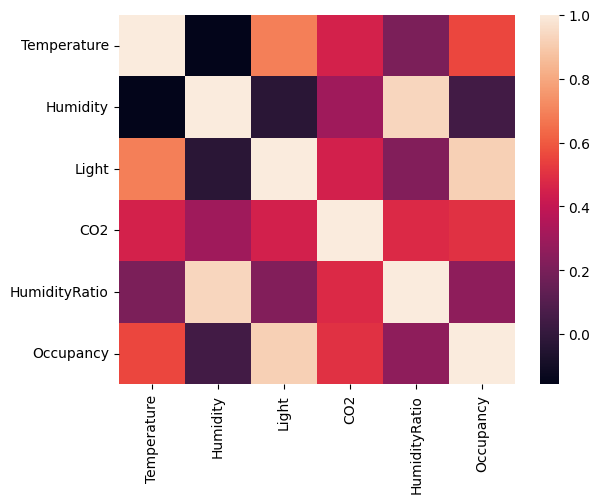

In [ ]:
# (2)
## WRITE ME
sns.heatmap(df.corr())
plt.show()

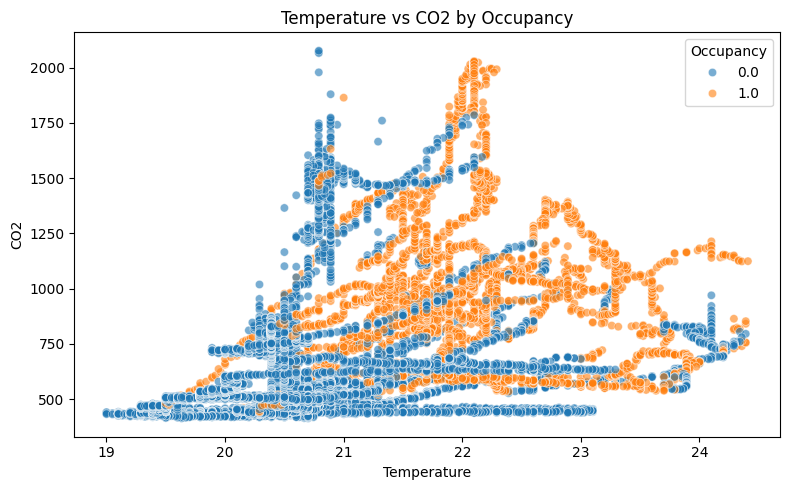

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Temperature",
    y="CO2",
    hue="Occupancy",
    alpha=0.6
)

plt.title("Temperature vs CO2 by Occupancy")
plt.xlabel("Temperature")
plt.ylabel("CO2")

plt.tight_layout()
plt.show()

(3) Which sensor data seems to have the strongest relationship with whether a room is occupied?

Answer: Looking at the correlation heatmap, light, temperature, and CO2 seem to be the best indicators of whether the room is occupied. Using feature engineering, which we will cover in the later parts of this course, we can maybe create new columns that will add more insight about the relationship so the model can improve its performance.

#### Task 2: Model Selection and Baseline Testing

Test at least three different classification algorithms we have covered (e.g. Logistic Regression, Decision Trees, KNN, or SVM). Remember that the Project Manager asked for a guarantee of reliability. Evaluate the performance of the models using accuracy via k-fold validation. Print out the baseline average accuracy for each model.

Hint: Look at your raw data. CO2 levels are in the hundreds or thousands, while Humidity Ratio is a tiny decimal like 0.004. If you are using models that measure distance, like KNN or SVM, what must you do to the data first?

In [ ]:
# Task 2
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.model_selection import cross_val_score

# Split into training and testing data
## WRITE ME
X = df[['Temperature','Humidity','Light','CO2','HumidityRatio']]
y = df['Occupancy']

# What should you probably do to the data before giving it to the models?
## WRITE ME
sc = StandardScaler()
X = sc.fit_transform(X)

# Create the three models you chose
## WRITE ME
logreg = LogisticRegression()
dt = DecisionTreeClassifier()
knn = KNeighborsClassifier()
svm = SVC()
models = [logreg,dt,knn,svm]

# Conduct 5-fold cross validation on the models you created (only on the training data!)
## WRITE ME
for model in models:
  scores = cross_val_score(model, X_train, y_train, cv=5)
  print(f"{model.__class__.__name__}: {scores.mean()}")

#### Task 3: Hyperparameter Tuning

Choose your best performing model from Task 2. Define a grid of hyperparameters for this model. For example, you can test different values of `max_depth` for a Decision Tree, `n_neighbors` for KNN, or `C` for SVM. Conduct hyperparameter tuning to squeeze out the highest accuracy score you possibly can, the print your final accuracy score.

In [ ]:
# Task 3
from sklearn.model_selection import GridSearchCV

# Prepare parameters for GridSearchCV
## WRITE ME
param_grid = {
    'n_neighbors': [3,4,5,6,7,8,9],
}

#Initialize GridSearchCV
## WRITE ME
gs = GridSearchCV(
    estimator=KNeighborsClassifier(),
    param_grid=param_grid,
    cv=5
)

# Perform hyperparameter tuning and build the best model
## WRITE ME
gs.fit(X_train, y_train)

# Display the results for both the training and testing data
## WRITE ME
print('Best cross-validation score: {:.3f}'.format(gs.best_score_))
print('Best parameters: {}'.format(gs.best_params_))
print('Test set score: {:.3f}'.format(gs.score(X_test, y_test)))
